# Step 8: Calibration and rejection of uncertain commands (Stage B)

**Research question, part 2:** can we stop unreliable predictions from becoming wheelchair commands? For every trial the system either **executes** the predicted command (left hand → LEFT, right hand → RIGHT, feet → FORWARD, tongue → STOP) or **rejects** it (no command; the wheelchair keeps its state).

| Step | What | Fitted on |
|---|---|---|
| Temperature scaling | p = softmax(z / T): makes the probabilities honest (calibrated) | labelled calibration data |
| Uncertainty score | predictive entropy H(p) (0 = certain, ln 4 = 1.386 = uniform); also 1 − max p and ensemble disagreement | – |
| Reject option | accept if H ≤ τ, otherwise no command | labelled calibration data |

**Calibration data never comes from the test session or the test person:**
- **within-subject:** leave-one-run-out cross-validation inside session T (held-out predictions at the final epoch count); one threshold for all users.
- **cross-subject, "other new users":** the predictions of the other 8 LOSO folds on *their* unseen subjects (the test subject is excluded).
- **cross-subject, "training subjects":** the 20% validation split of the 8 training subjects, for comparison.

**Operating points fixed in advance:** (1) accept 80% of the trials; (2) accepted commands ≥ 85% correct (within-subject) or ≥ 65% (cross-subject); (3) 80% coverage plus a simple artifact rule (reject if EEG peak-to-peak or EOG power is more than 3 robust z-scores above the session's median). Code: `src/uncertainty.py`, `experiments/run_calib.py`.

In [1]:
import json, subprocess, sys, warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT / "experiments"))
import run_calib as rc
import uncertainty as U
from data import SUBJECTS
FIG = ROOT / "results" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
S = json.loads((ROOT / "results" / "stageB" / "summary.json").read_text())
R, TESTS = S["settings"], S["tests"]
print("Run status:", (ROOT / "results" / "overnight_status_stageB.txt").read_text().strip().splitlines()[-1])
out = subprocess.run([sys.executable, str(ROOT / "tests" / "test_uncertainty.py")], capture_output=True, text=True, cwd=str(ROOT))
print("\n".join(l for l in out.stdout.splitlines() if l.startswith(("ok", "ALL"))))

Run status: [2026-11-16 00:17:10] ALL DONE - results in results/stageB/summary.md


ok  temperature scaling recovers a known temperature: T_true = 2.00, fitted 2.037
ok  ECE: calibrated probabilities 0.006, over-confident (logits x3) 0.195
ok  Brier/NLL: perfect = 0, uniform = 0.75 / ln 4
ok  entropy: uniform = ln 4, one-hot = 0; mutual information: identical members = 0, two confident members that disagree = ln 2
ok  risk-coverage: oracle score AURC 0.048 < random score AURC 0.265 (~error rate 0.30); oracle AUROC = 1
ok  thresholds: 80% coverage target -> 0.800; accuracy target 85% -> accepted accuracy 0.850 at coverage 0.320; unreachable target -> None
ok  safety metrics: coverage, accuracy of accepted commands and false commands per command
ok  robust z-score: median ~0, an outlier stands out
ALL TESTS PASSED


## 1. Checks on the inputs
Every final model's logits were recomputed from its checkpoint: the predictions agree 100% with the saved runs, and the rebuilt cross-subject validation split reproduces each model's training-time validation accuracy (so the "training subjects" calibration data really were held out).

In [2]:
exp = ROOT / "results" / "stageB" / "export"
w = [json.loads(p.read_text()) for p in (exp / "within_EA").glob("*.json")]
l = [json.loads(p.read_text()) for v in ("NOEA", "EA") for p in (exp / "loso" / v).glob("*.json")]
print(f"within-subject EA models: {len(w)}, min agreement with saved predictions {min(min(r['agree_with_saved'].values()) for r in w):.3f}")
print(f"cross-subject models: {len(l)}, min agreement {min(min(r['agree_with_saved'].values()) for r in l):.3f}, "
      f"max |val acc - training history| {max(abs(r['val_acc'] - r['val_acc_in_training_history']) for r in l):.4f}")
cv = pd.DataFrame([json.loads(p.read_text()) for v in ("NOEA", "EA") for p in (ROOT / "results" / "stageB" / "within_cv" / v).glob("*.json")])
print("Session-T CV accuracy of the calibration models (mean over 9 subjects x 6 folds x 5 seeds):")
print((100 * cv.groupby("variant").acc.mean()).round(2).to_string())

within-subject EA models: 45, min agreement with saved predictions 1.000
cross-subject models: 54, min agreement 1.000, max |val acc - training history| 0.0011


Session-T CV accuracy of the calibration models (mean over 9 subjects x 6 folds x 5 seeds):
variant
EA      71.19
NOEA    68.80


## 2. Calibration: are the probabilities honest?
ECE = expected calibration error (0 = a "70% sure" prediction is right 70% of the time). T > 1 means the model was **over-confident**.

In [3]:
NAMES = {"within_noEA": "within, no EA", "within_EA": "within, EA", "within_EA_online48": "within, EA (first 48 trials)",
         "cross_noEA": "cross, no EA", "cross_EA": "cross, EA", "cross_EA_online48": "cross, EA (first 48 trials)",
         "cross_noEA_srcval": "cross, no EA [calibrated on training subjects]", "cross_EA_srcval": "cross, EA [calibrated on training subjects]"}
rows = []
for k, lab in NAMES.items():
    for kind, m in R[k].items():
        rows.append({"setting": lab, "model": kind, "accuracy %": round(100 * m["accuracy"], 2), "T": round(m["T_mean"], 2),
                     "ECE raw %": round(100 * m["ece_raw"], 1), "ECE calibrated %": round(100 * m["ece_cal"], 1),
                     "NLL raw": round(m["nll_raw"], 3), "NLL cal": round(m["nll_cal"], 3),
                     "Brier raw": round(m["brier_raw"], 3), "Brier cal": round(m["brier_cal"], 3)})
calib = pd.DataFrame(rows); calib

,setting,model,accuracy %,T,ECE raw %,ECE calibrated %,NLL raw,NLL cal,Brier raw,Brier cal
0,"within, no EA",single,68.20,1.56,10.8,3.2,0.885,0.786,0.448,0.425
1,"within, no EA",ensemble,73.53,0.91,2.8,1.8,0.674,0.681,0.365,0.365
2,"within, EA",single,71.40,1.48,7.4,2.7,0.758,0.710,0.401,0.385
3,"within, EA",ensemble,76.16,0.79,4.2,2.9,0.590,0.591,0.324,0.323
4,"within, EA (first 48 trials)",single,69.18,1.48,10.0,3.9,0.857,0.772,0.441,0.415
5,"within, EA (first 48 trials)",ensemble,73.06,0.79,2.7,3.8,0.646,0.656,0.356,0.357
6,"cross, no EA",single,44.44,4.07,25.2,6.2,1.750,1.286,0.769,0.690
7,"cross, no EA",ensemble,45.60,3.21,19.6,6.8,1.548,1.276,0.718,0.682
8,"cross, EA",single,52.85,2.07,17.3,2.4,1.255,1.110,0.646,0.603
9,"cross, EA",ensemble,54.63,1.67,11.3,2.7,1.133,1.076,0.599,0.585


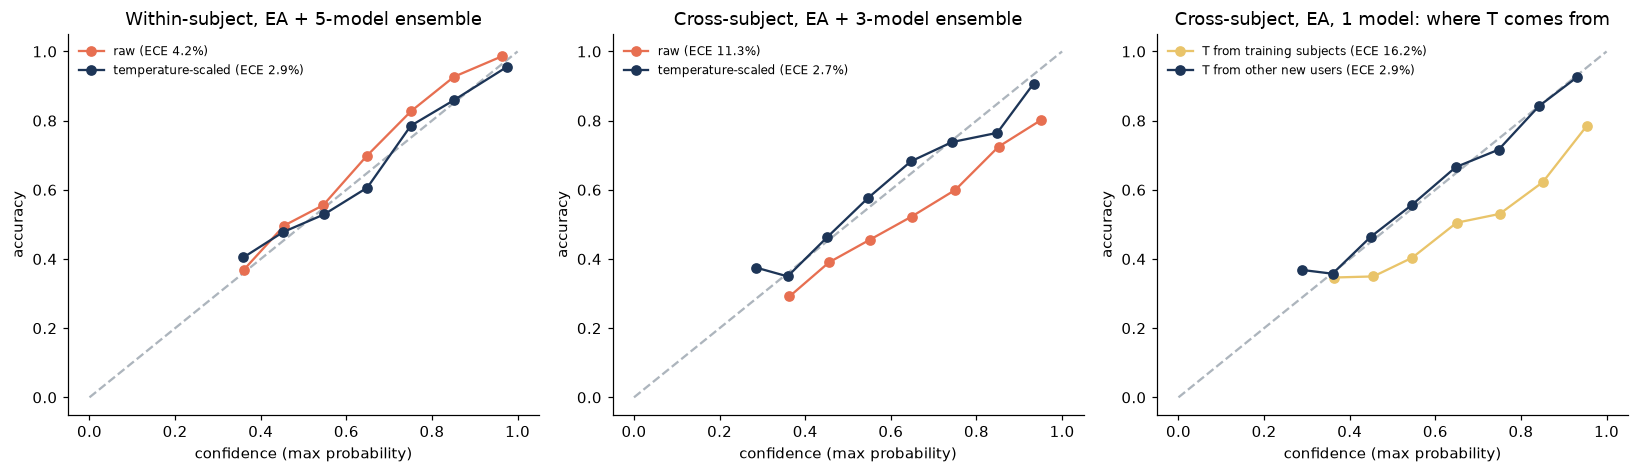

In [4]:
def pooled(setting, members):
    us = rc.evaluate(setting, members)
    cat = lambda k: np.concatenate([u[k] for u in us])
    return {k: cat(k) for k in ("test_y", "test_p", "test_p_raw", "test_H", "test_expert", "test_art")} | {"units": us}
def rel_plot(ax, p, y, label, color):
    rows = [r for r in U.reliability(p, y, 10) if r[2] >= 10]
    ax.plot([r[0] for r in rows], [r[1] for r in rows], "o-", color=color, label=f"{label} (ECE {100 * U.ece(p, y):.1f}%)")
W_EA = pooled("within_EA", rc.SEEDS_W); X_EA = pooled("cross_EA", rc.SEEDS_X)
X_EA_src = pooled("cross_EA_srcval", [0]); X_EA_oth = pooled("cross_EA", [0])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax in axes: ax.plot([0, 1], [0, 1], "--", color="#adb5bd"); ax.set_xlabel("confidence (max probability)"); ax.set_ylabel("accuracy")
rel_plot(axes[0], W_EA["test_p_raw"], W_EA["test_y"], "raw", "#e76f51"); rel_plot(axes[0], W_EA["test_p"], W_EA["test_y"], "temperature-scaled", "#1d3557")
axes[0].set_title("Within-subject, EA + 5-model ensemble")
rel_plot(axes[1], X_EA["test_p_raw"], X_EA["test_y"], "raw", "#e76f51"); rel_plot(axes[1], X_EA["test_p"], X_EA["test_y"], "temperature-scaled", "#1d3557")
axes[1].set_title("Cross-subject, EA + 3-model ensemble")
rel_plot(axes[2], X_EA_src["test_p"], X_EA_src["test_y"], "T from training subjects", "#e9c46a")
rel_plot(axes[2], X_EA_oth["test_p"], X_EA_oth["test_y"], "T from other new users", "#1d3557")
axes[2].set_title("Cross-subject, EA, 1 model: where T comes from")
for ax in axes: ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "08_reliability.png", bbox_inches="tight"); plt.show()

**Reading:** a single EEGNet is **over-confident**: its stated confidence is higher than its real accuracy. Temperature scaling (T > 1 softens the probabilities) fixes most of this. The calibration error (ECE) falls from 10.8% to 3.2% within-subject without EA, from 7.4% to 2.7% with EA, and from 17.3% to 2.4% for cross-subject with EA. Averaging 5 models already gives nearly honest probabilities (ECE 2.8–4.2% before scaling), and the fitted T < 1 shows the ensemble is slightly *under*-confident. For new users, calibrating on the **training subjects' own validation data does not work** (T ≈ 1, ECE stays 17–27%): models are much more accurate on people they were trained on (val ≈ 69–77%) than on a new person (≈ 44–55%). Calibration has to come from *other new users*. This is why the 'other new users' setting is the one we use.

## 3. Does uncertainty point at the wrong predictions?
AUROC: how well a score separates wrong from correct predictions (0.5 = chance, 1 = perfect). AURC: area under the risk–coverage curve (lower = better). The curves show the error rate among accepted commands when only the most certain trials are accepted.

In [5]:
rows = []
for k in ("within_noEA", "within_EA", "cross_noEA", "cross_EA"):
    for kind, m in R[k].items():
        rows.append({"setting": NAMES[k], "model": kind, **{f"AUROC {s}": round(v, 3) for s, v in m["auroc"].items()}, "AURC": round(m["aurc"], 3)})
pd.DataFrame(rows)

,setting,model,AUROC entropy,AUROC maxprob,AURC,AUROC mutual_information
0,"within, no EA",single,0.762,0.771,0.147,NaN
1,"within, no EA",ensemble,0.783,0.792,0.107,0.736
2,"within, EA",single,0.785,0.791,0.120,NaN
3,"within, EA",ensemble,0.807,0.815,0.085,0.769
4,"cross, no EA",single,0.552,0.579,0.513,NaN
5,"cross, no EA",ensemble,0.555,0.582,0.502,0.558
6,"cross, EA",single,0.644,0.654,0.351,NaN
7,"cross, EA",ensemble,0.654,0.669,0.332,0.610


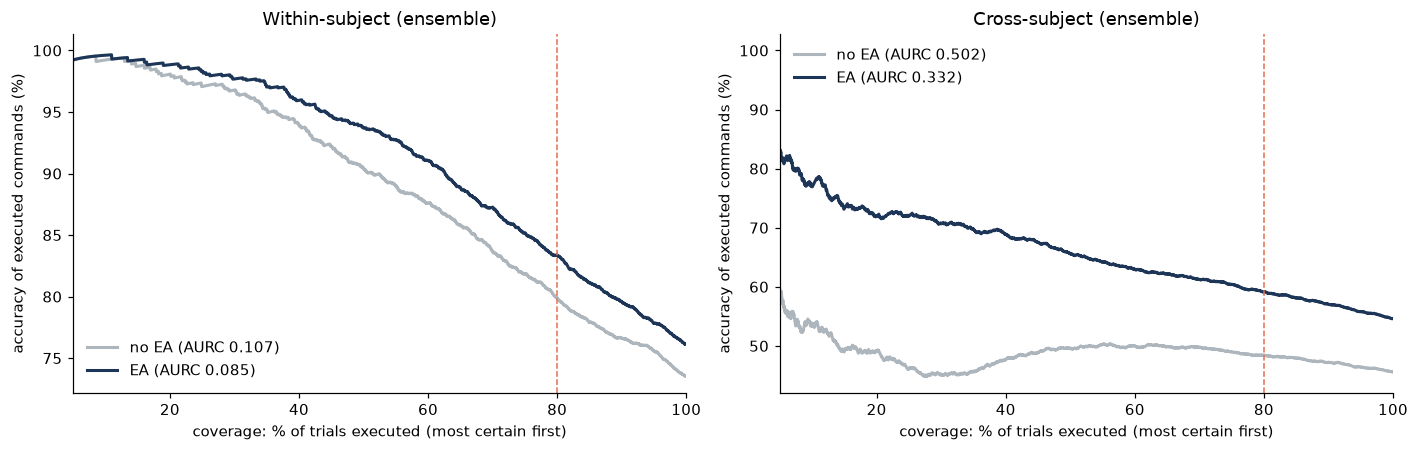

In [6]:
W_no = pooled("within_noEA", rc.SEEDS_W); X_no = pooled("cross_noEA", rc.SEEDS_X)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, pairs, title in [(axes[0], [(W_no, "no EA", "#adb5bd"), (W_EA, "EA", "#1d3557")], "Within-subject (ensemble)"),
                         (axes[1], [(X_no, "no EA", "#adb5bd"), (X_EA, "EA", "#1d3557")], "Cross-subject (ensemble)")]:
    for d, lab, col in pairs:
        cov, risk = U.risk_coverage(d["test_H"], d["test_p"].argmax(1) == d["test_y"])
        ax.plot(100 * cov, 100 * (1 - risk), color=col, lw=2, label=f"{lab} (AURC {U.aurc(d['test_H'], d['test_p'].argmax(1) == d['test_y']):.3f})")
    ax.axvline(80, color="#e76f51", ls="--", lw=1); ax.set_xlabel("coverage: % of trials executed (most certain first)")
    ax.set_ylabel("accuracy of executed commands (%)"); ax.set_title(title); ax.legend(frameon=False); ax.set_xlim(5, 100)
fig.tight_layout(); fig.savefig(FIG / "08_risk_coverage.png", bbox_inches="tight"); plt.show()

**Reading:** within-subject, entropy separates wrong from correct predictions well (AUROC 0.76–0.81, where 0.5 is chance). EA and the ensemble both improve it, and EA + ensemble is best (0.807, AURC 0.085). 1 − max p is equally good (0.815), but ensemble disagreement (mutual information, 0.77) is worse than entropy. For a **new user without EA** the uncertainty is almost useless (AUROC 0.55). The model is wrong about as often when it is sure as when it is unsure, so rejection can barely help. **With EA** it improves to 0.65 and AURC drops from 0.50 to 0.33. EA does not just raise accuracy: it makes the model's confidence meaningful on a new person.

## 4. The reject option at the pre-set operating points
Thresholds come from the calibration data; the numbers below are what happens on the **test** data. "False commands" = executed commands that were wrong, per 100 trials.

In [7]:
def op_rows(k, kind):
    m = R[k][kind]
    rows = [{"operating point": "no rejection", "coverage %": 100.0, "accepted accuracy %": round(100 * m["accuracy"], 2),
             "false commands / 100 trials": round(m["no_rejection_false_per_100"], 1)}]
    for op, lab in [("cov80", "accept 80% (threshold from calibration data)"), ("acc_target", "target accuracy of accepted commands"),
                    ("cov80_artifact", "80% + artifact rule")]:
        o = m[op]
        rows.append({"operating point": lab, "coverage %": None if o is None else round(100 * o["coverage"], 1),
                     "accepted accuracy %": None if o is None else round(100 * o["accepted_accuracy"], 2),
                     "false commands / 100 trials": None if o is None else round(o["false_per_100"], 1)})
    return pd.DataFrame(rows).assign(setting=NAMES[k], model=kind)
pd.concat([op_rows(k, kind) for k in ("within_EA", "within_EA_online48", "cross_EA", "cross_EA_online48") for kind in ("ensemble", "single")]).reset_index(drop=True)

,operating point,coverage %,accepted accuracy %,false commands / 100 trials,setting,model
0,no rejection,100.0,76.16,23.8,"within, EA",ensemble
1,accept 80% (threshold from calibration data),82.9,81.99,14.9,"within, EA",ensemble
2,target accuracy of accepted commands,81.2,82.76,14.0,"within, EA",ensemble
3,80% + artifact rule,83.7,79.48,17.2,"within, EA",ensemble
4,no rejection,100.0,71.40,28.6,"within, EA",single
5,accept 80% (threshold from calibration data),81.6,78.17,17.8,"within, EA",single
6,target accuracy of accepted commands,66.2,83.46,10.9,"within, EA",single
7,80% + artifact rule,83.1,75.40,20.4,"within, EA",single
8,no rejection,100.0,73.06,26.9,"within, EA (first 48 trials)",ensemble
9,accept 80% (threshold from calibration data),82.6,79.72,16.8,"within, EA (first 48 trials)",ensemble


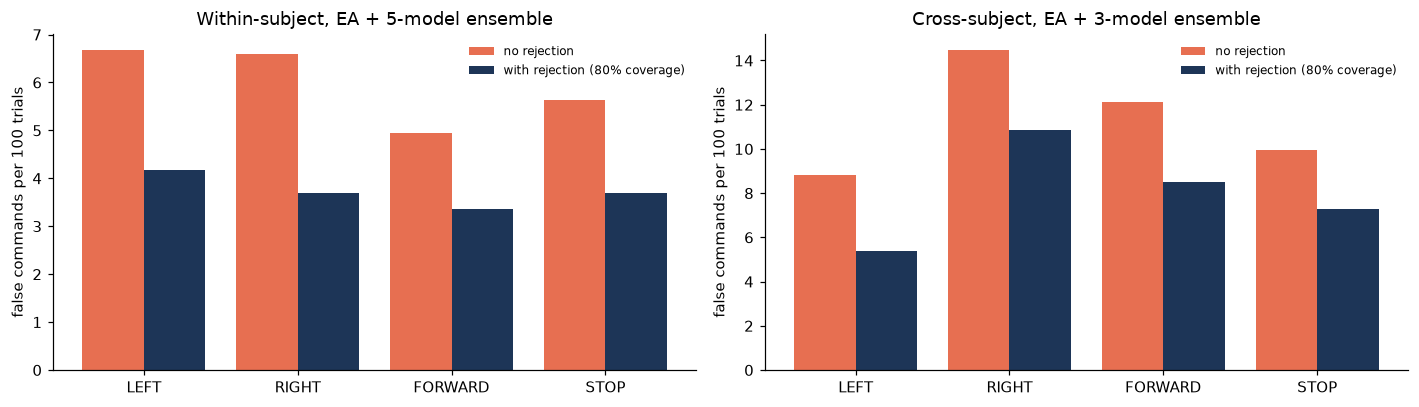

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, k, title in [(axes[0], "within_EA", "Within-subject, EA + 5-model ensemble"), (axes[1], "cross_EA", "Cross-subject, EA + 3-model ensemble")]:
    m = R[k]["ensemble"]
    before = {c: 0 for c in U.COMMANDS}
    d = W_EA if k == "within_EA" else X_EA
    pred = d["test_p"].argmax(1); wrong = pred != d["test_y"]
    before = {c: 100 * (wrong & (pred == i)).mean() for i, c in enumerate(U.COMMANDS)}
    after = m["cov80"]["false_by_command_per_100"]
    x = np.arange(4)
    ax.bar(x - 0.2, [before[c] for c in U.COMMANDS], 0.4, color="#e76f51", label="no rejection")
    ax.bar(x + 0.2, [after[c] for c in U.COMMANDS], 0.4, color="#1d3557", label="with rejection (80% coverage)")
    ax.set_xticks(x, U.COMMANDS); ax.set_ylabel("false commands per 100 trials"); ax.set_title(title); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "08_false_commands.png", bbox_inches="tight"); plt.show()

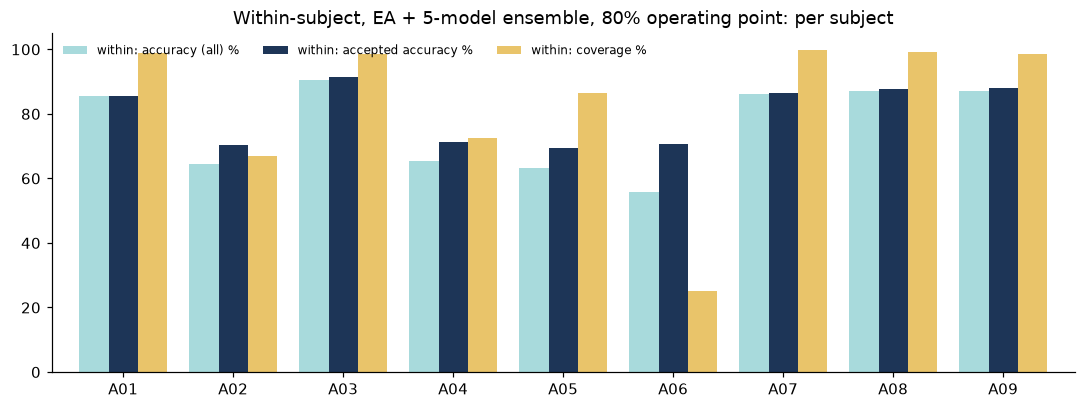

,within: accuracy (all) %,within: coverage %,within: accepted accuracy %,cross: accuracy (all) %,cross: coverage %,cross: accepted accuracy %
A01,85.4,99.0,85.6,71.2,96.2,72.2
A02,64.6,67.0,70.5,34.0,54.2,41.7
A03,90.6,98.6,91.5,79.2,89.2,83.3
A04,65.3,72.6,71.3,46.2,68.1,48.5
A05,63.2,86.5,69.5,35.4,80.6,36.6
A06,55.9,25.0,70.8,47.9,81.2,48.3
A07,86.1,99.7,86.4,40.3,56.9,43.3
A08,87.2,99.3,87.8,72.6,87.2,76.1
A09,87.2,98.6,88.0,64.9,97.6,65.8


In [9]:
bs = R["within_EA"]["ensemble"]["by_subject"]; bx = R["cross_EA"]["ensemble"]["by_subject"]
per = pd.DataFrame({"within: accuracy (all) %": {s: 100 * bs[s]["accuracy"] for s in SUBJECTS},
                    "within: coverage %": {s: 100 * bs[s]["cov80"]["coverage"] for s in SUBJECTS},
                    "within: accepted accuracy %": {s: 100 * bs[s]["cov80"]["accepted_accuracy"] for s in SUBJECTS},
                    "cross: accuracy (all) %": {s: 100 * bx[s]["accuracy"] for s in SUBJECTS},
                    "cross: coverage %": {s: 100 * bx[s]["cov80"]["coverage"] for s in SUBJECTS},
                    "cross: accepted accuracy %": {s: 100 * bx[s]["cov80"]["accepted_accuracy"] for s in SUBJECTS}}).round(1)
ax = per[["within: accuracy (all) %", "within: accepted accuracy %", "within: coverage %"]].plot.bar(figsize=(12, 4), rot=0, width=0.8,
                                                                                                   color=["#a8dadc", "#1d3557", "#e9c46a"])
ax.set_ylim(0, 105); ax.set_title("Within-subject, EA + 5-model ensemble, 80% operating point: per subject"); ax.legend(frameon=False, fontsize=8, ncol=3)
ax.figure.savefig(FIG / "08_per_subject.png", bbox_inches="tight"); plt.show()
per

**Reading:** at 80% coverage (about 1 in 5 trials gives no command), within-subject EA + ensemble raises the accuracy of executed commands from 76.2% to **82.0%**. False commands drop from 23.8 to **14.9 per 100 trials** (−37%). Cross-subject EA + ensemble goes from 54.6% to 59.5%, and false commands from 45.4 to 32.0 per 100 (−30%). The accuracy targets fixed in advance were **not fully met**: the threshold chosen for 85% on session-T CV gives 82.8% on session E (at 81% coverage), and the 65% cross-subject target gives 62.8% (at 58% coverage). Without EA the 65% target is unreachable for a new user. Thresholds chosen on calibration data come out a little optimistic on new data. False commands are spread fairly evenly over LEFT/RIGHT/FORWARD/STOP within-subject. For a new user, RIGHT and FORWARD produce the most false commands. **Per subject**, the one threshold adapts on its own. Good users keep almost all their commands (A01, A03, A07–A09: 99–100% coverage). Weak users get many trials rejected: A06 keeps only 25%, but their accuracy rises from 55.9% to 70.6%. A02 and A04 keep about 70%. The system is cautious exactly where it should be.

## 5. Stage C: does Euclidean Alignment change the rejection behaviour?
Same rule, same operating point, with and without EA. Per-subject paired Wilcoxon tests (9 subjects).

In [10]:
rows = []
for k, v in TESTS.items():
    a, kind, metric = [x.strip() for x in k.split("|")]
    rows.append({"comparison": a, "model": kind, "metric": metric, "EA": round(v["mean_a"], 4), "no EA": round(v["mean_b"], 4),
                 "EA better for": f"{v['a_better_for']}/9", "Wilcoxon p": round(v["wilcoxon_p"], 3)})
stagec = pd.DataFrame(rows); stagec[stagec.model == "ensemble"]

,comparison,model,metric,EA,no EA,EA better for,Wilcoxon p
0,within_EA vs within_noEA,ensemble,aurc,0.1182,0.1387,7/9,0.098
1,within_EA vs within_noEA,ensemble,ece_cal,0.0614,0.0778,5/9,0.301
2,within_EA vs within_noEA,ensemble,false_per_100_at_cov80,14.9306,17.9012,6/9,0.312
3,within_EA vs within_noEA,ensemble,accepted_accuracy_at_cov80,0.8016,0.7733,5/9,0.359
8,within_EA_online48 vs within_noEA_from48,ensemble,aurc,0.1351,0.1492,5/9,0.734
9,within_EA_online48 vs within_noEA_from48,ensemble,ece_cal,0.0747,0.0839,4/9,1.000
10,within_EA_online48 vs within_noEA_from48,ensemble,false_per_100_at_cov80,16.7593,18.2407,3/9,0.984
11,within_EA_online48 vs within_noEA_from48,ensemble,accepted_accuracy_at_cov80,0.7788,0.7660,4/9,0.910
16,cross_EA vs cross_noEA,ensemble,aurc,0.3674,0.4531,9/9,0.004
17,cross_EA vs cross_noEA,ensemble,ece_cal,0.1327,0.1848,6/9,0.164


**Reading (Stage C, EA vs no EA):** for **new users**, EA gives better rejection for **every one of the 9 subjects** (AURC, and accuracy of accepted commands at 80% coverage; p = 0.004 for single and ensemble). This holds in the realistic online setting too (EA from the first 48 trials: p = 0.004–0.027). Within-subject, a single EA model is significantly better calibrated (ECE p = 0.008) and gives fewer false commands (p = 0.039). With the 5-model ensemble the gains (AURC 7/9 subjects) are not significant, because the ensemble already calibrates well on its own.

## 6. Which trials are rejected? Artifacts
Expert-marked artifact trials (code 1023, about 9% of session E) are **not** used by the system; they only serve to check what gets rejected.

In [11]:
rows = []
for k in ("within_EA", "cross_EA"):
    m = R[k]["ensemble"]
    for op, lab in [("cov80", "entropy only"), ("cov80_artifact", "entropy + artifact rule")]:
        o = m[op]
        rows.append({"setting": NAMES[k], "rule": lab, "coverage %": round(100 * o["coverage"], 1), "accepted accuracy %": round(100 * o["accepted_accuracy"], 2),
                     "false / 100": round(o["false_per_100"], 1), "expert-marked trials rejected %": round(100 * o["rejected_expert_marked"], 1),
                     "clean trials rejected %": round(100 * o["rejected_clean"], 1)})
print("Artifact detector on the test data:", {k: round(100 * v, 1) for k, v in R["cross_EA"]["ensemble"]["artifact_detector"].items()}, "(%)")
pd.DataFrame(rows)

Artifact detector on the test data: {'flagged': 8.0, 'expert_marked_flagged': 23.2, 'flagged_that_are_expert_marked': 25.1} (%)


,setting,rule,coverage %,accepted accuracy %,false / 100,expert-marked trials rejected %,clean trials rejected %
0,"within, EA",entropy only,82.9,81.99,14.9,36.2,15.3
1,"within, EA",entropy + artifact rule,83.7,79.48,17.2,42.9,13.8
2,"cross, EA",entropy only,79.0,59.52,32.0,17.4,21.3
3,"cross, EA",entropy + artifact rule,79.4,58.28,33.1,33.0,19.4


**Reading:** the simple artifact rule **does not help**: at the same coverage it lowers the accuracy of accepted commands by 2–3 points and increases false commands. Two reasons. (1) The rule catches only 23% of the expert-marked artifact trials (and only 25% of what it flags is expert-marked). (2) The trials it flags are hardly worse than the rest: 73.4% vs 76.4% correct (within, EA). The expert-marked trials *are* worse (63.8% vs 77.3%), and entropy rejection alone already rejects 36–41% of them within-subject, compared with 15% of clean trials. Uncertainty already handles artifacts that matter. A better artifact detector is part of the deferred plan (R2).

## 7. Summary of Stage B

**Stage B in short:**
1. **Calibration works:** temperature scaling brings the calibration error down to about 2–4%. For a new user, calibrate on other new users, not on the training subjects (that stays 17–27% off).
2. **Rejection reduces false commands by about a third:** EA + 5-model ensemble at 80% coverage gives 82.0% correct commands and 14.9 false per 100 trials within-subject (instead of 23.8). For a new user it gives 59.5% and 32.0 per 100 (instead of 45.4).
3. **Stage C:** EA makes the uncertainty meaningful for a new user (AUROC 0.55 → 0.65, better rejection for 9/9 subjects, p = 0.004). Without EA, rejection is nearly useless across subjects.
4. **Not achieved:** the accuracy targets fixed in advance (85% / 65%) came out at 82.8% / 62.8%, and the artifact rule did not help. Both are reported as they are.
5. **Recommended system:** EA + 5-model ensemble + temperature scaling + entropy threshold at 80% coverage, with no artifact rule.